# Experiment: Inspect Disk Backed ChangBai CC Cube

Objective:
- Open an existing disk-backed HDF5 cube with shape `(ndate, nshot, nt, noffset)`.
- Inspect metadata, slice one fixed shot across all dates, and make quick plots.
- Keep notebook responsibility limited to HDF5 reading and visualization.

Success criteria:
- The notebook opens an existing `cc_cube_by_date.h5` without touching the original `.mat` files.
- Example cells can read `[:, ishot, :, :]`, inspect metadata, and generate summary plots.


In [ ]:
# Setup: imports, plotting defaults, and notebook paths
from __future__ import annotations

from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.sans-serif"] = ["Times New Roman"]
plt.rcParams["figure.dpi"] = 120

ROOT_DIR = Path("../outputs/cc_tsi_plot_outputs_ChangBai").resolve()
OUTPUT_H5 = ROOT_DIR / "cc_cube_by_date.h5"
meta_csv = ROOT_DIR / "cc_cube_index.csv"
shot_index = 10

ROOT_DIR, OUTPUT_H5


(PosixPath('/csim2/zhangzhiyu/MyProjects/dasQt_examples/03_ccf/outputs/cc_tsi_plot_outputs_ChangBai'),
 PosixPath('/csim2/zhangzhiyu/MyProjects/dasQt_examples/03_ccf/outputs/cc_tsi_plot_outputs_ChangBai/cc_cube_by_date.h5'))

## Plan

- Open the existing HDF5 cube and print global shape plus chunk layout.
- Read the CSV index if it exists, so the date-to-file mapping remains visible.
- Slice one fixed shot across all dates with `h5f["cc"][:, shot_index, :, :]`.
- Plot one date / one shot image and simple cross-date statistics.


In [3]:
# Helpers: HDF5 summary and optional CSV index loading
def summarize_hdf5(output_h5: Path) -> dict[str, object]:
    with h5py.File(output_h5, "r") as h5f:
        return {
            "cc_shape": tuple(int(x) for x in h5f["cc"].shape),
            "cc_dtype": str(h5f["cc"].dtype),
            "date_count": int(h5f["date_labels"].shape[0]),
            "root_dir": h5f.attrs["root_dir"],
            "created_at": h5f.attrs.get("created_at", ""),
            "chunk_mode": h5f.attrs.get("chunk_mode", ""),
            "chunk_shape": tuple(int(x) for x in h5f["cc"].chunks),
        }


def load_index_csv(meta_csv: Path) -> pd.DataFrame | None:
    if not meta_csv.exists():
        print(f"Index CSV not found: {meta_csv}")
        return None
    return pd.read_csv(meta_csv)


if not OUTPUT_H5.exists():
    raise FileNotFoundError(
        f"HDF5 file not found: {OUTPUT_H5}. Run `uv run python tools/build_cc_h5_cube.py ...` first."
    )


## Inspect Global Metadata

This stage only opens the existing HDF5 cube and its optional CSV index.


In [4]:
summary = summarize_hdf5(OUTPUT_H5)
summary


{'cc_shape': (13, 184, 999, 50),
 'cc_dtype': 'float32',
 'date_count': 13,
 'root_dir': '/csim2/zhangzhiyu/MyProjects/dasQt_examples/03_ccf/outputs/cc_tsi_plot_outputs_ChangBai',
 'created_at': '2026-05-16T20:54:05',
 'chunk_mode': 'single_shot_across_dates',
 'chunk_shape': (1, 1, 256, 50)}

In [5]:
index_df = load_index_csv(META_CSV)
if index_df is not None:
    display(index_df.head(20))


,date_label,folder_path,mat_path,candidate_count,candidate_paths,ignored_paths,selected_name,file_size_mb,raw_data_shape,data_dtype,nshot,nt,noffset
0,2025-03-23,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0004.mat,35.061867,"(184, 999, 50)",single,184,999,50
1,2025-03-24,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0001.mat,35.061409,"(184, 999, 50)",single,184,999,50
2,2025-03-25,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0003.mat,35.061714,"(184, 999, 50)",single,184,999,50
3,2025-03-26,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0005.mat,35.062019,"(184, 999, 50)",single,184,999,50
4,2025-03-27,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0019.mat,35.064156,"(184, 999, 50)",single,184,999,50
5,2025-03-28,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0019.mat,35.064156,"(184, 999, 50)",single,184,999,50
6,2025-03-29,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0018.mat,35.064003,"(184, 999, 50)",single,184,999,50
7,2025-03-30,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0019.mat,35.064156,"(184, 999, 50)",single,184,999,50
8,2025-03-31,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0019.mat,35.064156,"(184, 999, 50)",single,184,999,50
9,2025-04-01,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,/csim2/zhangzhiyu/MyProjects/dasQt_examples/03...,1,"[""/csim2/zhangzhiyu/MyProjects/dasQt_examples/...",[],restack_0001_nall_idx0000-0019.mat,35.064156,"(184, 999, 50)",single,184,999,50


## Re-Open The Cube And Inspect Slices

These examples operate directly on the HDF5-backed dataset.


In [6]:
with h5py.File(OUTPUT_H5, "r") as h5f:
    cc_shape = tuple(int(x) for x in h5f["cc"].shape)
    date_labels = [x.decode("utf-8") if isinstance(x, bytes) else str(x) for x in h5f["date_labels"][:]]
    print("cc shape:", cc_shape)
    print("chunk shape:", tuple(int(x) for x in h5f["cc"].chunks))
    print("first dates:", date_labels[: min(5, len(date_labels))])
    first_cube = h5f["cc"][0]
    print("first date cube shape:", first_cube.shape)


cc shape: (13, 184, 999, 50)
chunk shape: (1, 1, 256, 50)
first dates: ['2025-03-23', '2025-03-24', '2025-03-25', '2025-03-26', '2025-03-27']
first date cube shape: (184, 999, 50)


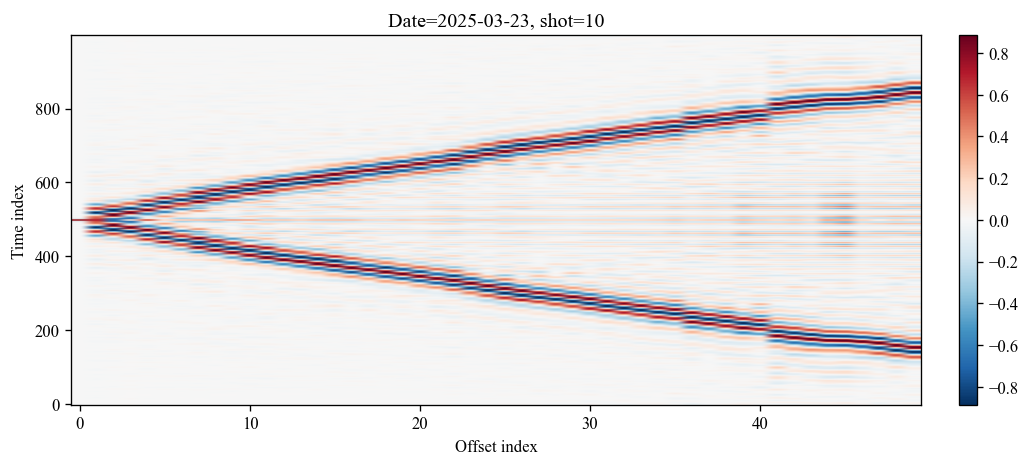

In [ ]:
# Example 1: show one date / one shot image
data_index = 0

with h5py.File(OUTPUT_H5, "r") as h5f:
    if shot_index >= h5f["cc"].shape[1]:
        raise IndexError(f"shot_index={shot_index} out of range for nshot={h5f['cc'].shape[1]}")
    cc_slice = h5f["cc"][data_index, shot_index]
    date_label = h5f["date_labels"][data_index]
    date_label = date_label.decode("utf-8") if isinstance(date_label, bytes) else str(date_label)

vmax = float(np.percentile(np.abs(cc_slice), 99))
vmax = 1.0 if vmax == 0 else vmax
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(cc_slice, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="lower")
ax.set_title(f"Date={date_label}, shot={shot_index}")
ax.set_xlabel("Offset index")
ax.set_ylabel("Time index")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


In [ ]:
# Example 2: load one shot across all dates
with h5py.File(OUTPUT_H5, "r") as h5f:
    if shot_index >= h5f["cc"].shape[1]:
        raise IndexError(f"shot_index={shot_index} out of range for nshot={h5f['cc'].shape[1]}")
    shot_cube = h5f["cc"][:, shot_index, :, :]
    date_labels = [x.decode("utf-8") if isinstance(x, bytes) else str(x) for x in h5f["date_labels"][:]]

print("shot cube shape:", shot_cube.shape)
shot_cube.shape


shot cube shape: (13, 999, 50)


(13, 999, 50)

In [9]:
# Example 3: summary statistics for one shot across all dates
mean_trace_by_date = shot_cube.mean(axis=(1, 2))
shot_energy_by_date = np.sqrt((shot_cube ** 2).mean(axis=(1, 2)))
summary_df = pd.DataFrame(
    {
        "date_label": date_labels,
        "mean_amplitude": mean_trace_by_date,
        "rms_amplitude": shot_energy_by_date,
    }
)
display(summary_df.head(20))


,date_label,mean_amplitude,rms_amplitude
0,2025-03-23,-5.727774e-11,0.199732
1,2025-03-24,1.527406e-10,0.234072
2,2025-03-25,5.393653e-10,0.150769
3,2025-03-26,-8.114346e-10,0.155204
4,2025-03-27,1.909258e-11,0.162179
5,2025-03-28,-1.670601e-10,0.143032
6,2025-03-29,3.818516e-11,0.146997
7,2025-03-30,2.291110e-10,0.184780
8,2025-03-31,-8.591661e-11,0.145266
9,2025-04-01,4.677682e-10,0.150827


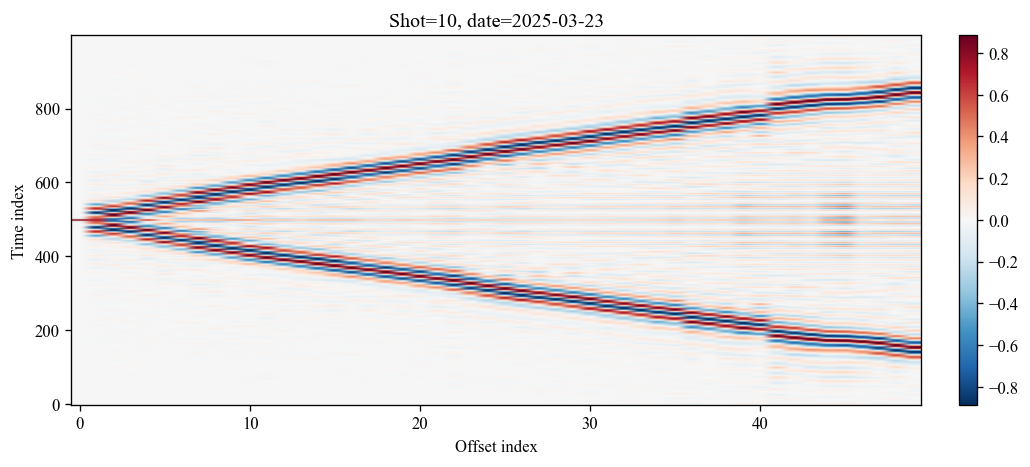

In [ ]:
# Example 4: quick image browser for one fixed shot across dates
data_index = 0
date_label = date_labels[data_index]
cc_slice = shot_cube[data_index]

vmax = float(np.percentile(np.abs(cc_slice), 99))
vmax = 1.0 if vmax == 0 else vmax
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(cc_slice, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="lower")
ax.set_title(f"Shot={shot_index}, date={date_label}")
ax.set_xlabel("Offset index")
ax.set_ylabel("Time index")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


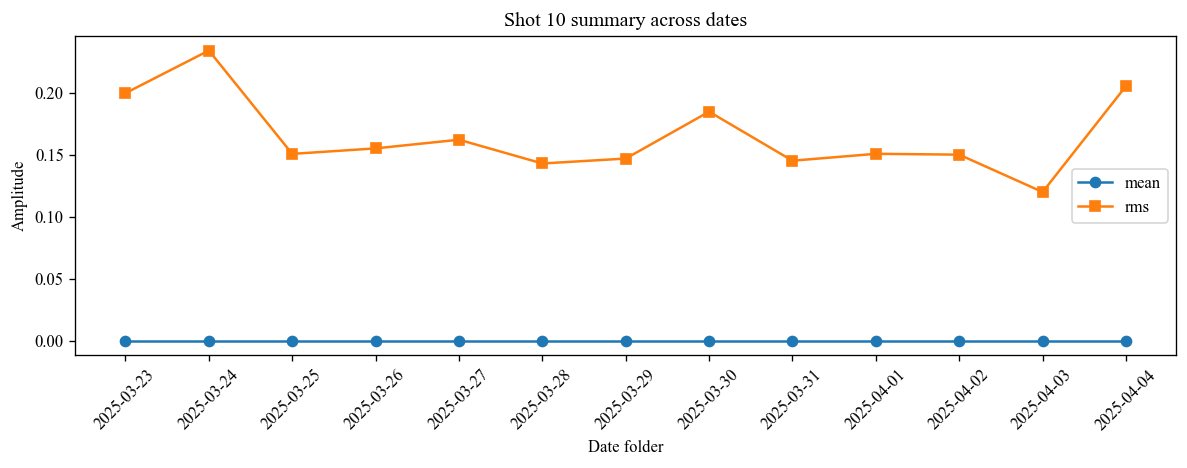

In [ ]:
# Example 5: date-wise mean / rms plot for the selected shot
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_labels, mean_trace_by_date, marker="o", label="mean")
ax.plot(date_labels, shot_energy_by_date, marker="s", label="rms")
ax.set_title(f"Shot {shot_index} summary across dates")
ax.set_xlabel("Date folder")
ax.set_ylabel("Amplitude")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
plt.show()


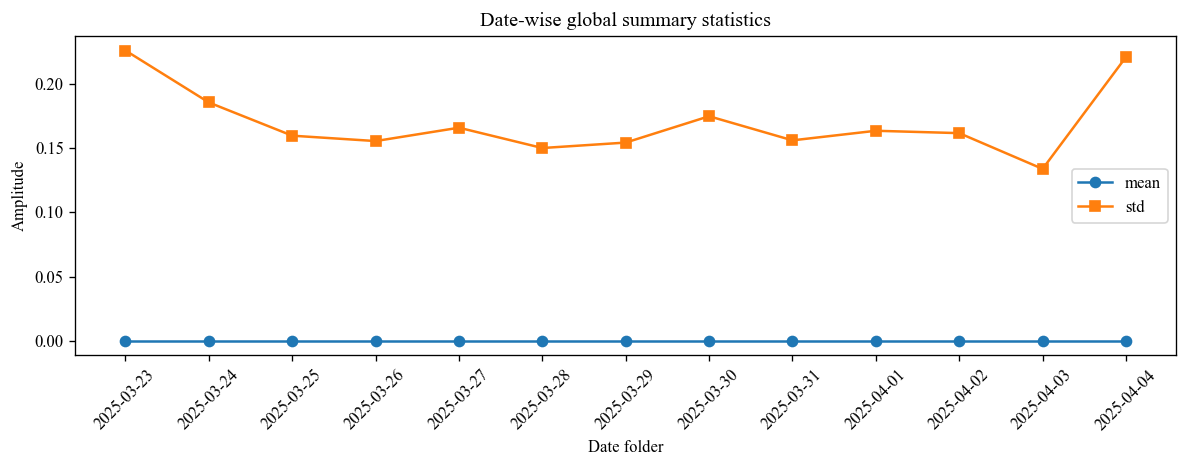

In [12]:
# Example 6: global date-wise mean / std and a quick sanity plot
with h5py.File(OUTPUT_H5, "r") as h5f:
    cc = h5f["cc"]
    date_labels = [x.decode("utf-8") if isinstance(x, bytes) else str(x) for x in h5f["date_labels"][:]]
    date_mean = np.asarray([cc[i].mean() for i in range(cc.shape[0])], dtype=float)
    date_std = np.asarray([cc[i].std() for i in range(cc.shape[0])], dtype=float)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_labels, date_mean, marker="o", label="mean")
ax.plot(date_labels, date_std, marker="s", label="std")
ax.set_title("Date-wise global summary statistics")
ax.set_xlabel("Date folder")
ax.set_ylabel("Amplitude")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
plt.show()


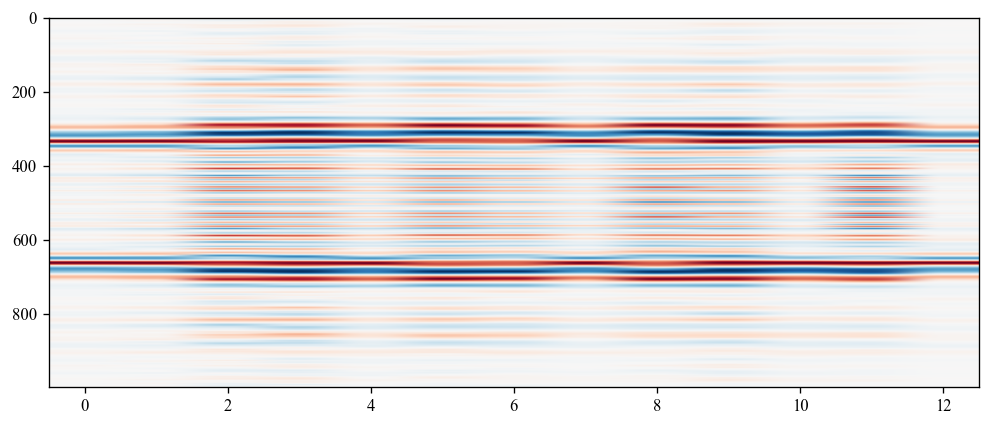

In [ ]:

shot_index = 180
OFFSET_INDEX = 30

with h5py.File(OUTPUT_H5, "r") as h5f:
    if shot_index >= h5f["cc"].shape[1]:
        raise IndexError(f"shot_index={shot_index} out of range for nshot={h5f['cc'].shape[1]}")
    cc_slice = h5f["cc"][:, shot_index, :, OFFSET_INDEX]

fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(cc_slice.T, aspect='auto', cmap='RdBu')


## Results

- The notebook depends only on `cc_cube_by_date.h5` and optional `cc_cube_index.csv`.
- Fixed-shot cross-date access should be efficient because the CLI writes a shot-oriented chunk layout by default.
- The original `.mat` to HDF5 conversion is intentionally removed from the notebook.


## Next Steps

- If you need a fresh cube, rerun `uv run python tools/build_cc_h5_cube.py ...` outside the notebook.
- Add downstream analysis cells that compute cross-date changes for fixed shots or offsets.
- If you later want interactivity, add widgets around `shot_index` and `data_index`.
